**Выполнил Ожиганов В. В., М26-555**

# Статистический анализ двух бинарных выборок

## 📊 Условие задачи

### Исходные данные:
- **Две бинарные выборки** с вероятностями успеха:
  - $p_1 = 0.35$ (первая выборка)
  - $p_2 = 0.40$ (вторая выборка)
- **Уровень значимости**: $\alpha = 0.05$ (p-value)
- **Минимальный детектируемый эффект (MDE)**: $\delta = |p_2 - p_1| = 0.05$

### Поставленные задачи:

#### 1. 📈 Определение минимального размера выборки
**Цель**: Найти минимальное количество элементов $n$ в каждой выборке, необходимое для детекции MDE с заданной мощностью теста ($1 - \beta = 0.8$).

**Формула для расчета**:
$$
n = \frac{(z_{1-\alpha/2} \cdot \sqrt{2 \cdot \bar{p} \cdot (1-\bar{p})} + z_{1-\beta} \cdot \sqrt{p_1(1-p_1) + p_2(1-p_2)})^2}{(p_1 - p_2)^2}
$$

где:
- $\bar{p} = \frac{p_1 + p_2}{2}$ - объединенная пропорция
- $z_{1-\alpha/2}$ - квантиль нормального распределения для двустороннего теста
- $z_{1-\beta}$ - квантиль нормального распределения для мощности теста

#### 2. 🔄 Преобразование распределений через ЦПТ
**Цель**: Используя Центральную Предельную Теорему (ЦПТ), преобразовать биномиальные распределения к нормальным.

**Формулы преобразования**:
- Для выборки размера $n$ с вероятностью $p$:
  $$
  \text{Среднее: } \mu = p
  $$
  $$
  \text{Стандартное отклонение: } \sigma = \sqrt{\frac{p(1-p)}{n}}
  $$
- Получаем нормальные распределения:
  - Первая выборка: $N(\mu_1, \sigma_1)$
  - Вторая выборка: $N(\mu_2, \sigma_2)$

#### 3. 📊 Визуализация распределений и ошибок
**Требуется построить два графика**:

**График 1**: Двусторонняя альтернатива
- Распределения обеих выборок
- Критические области для ошибки I рода ($\alpha$)
- Область ошибки II рода ($\beta$)

**График 2**: Односторонняя альтернатива ($p_1 > p_2$)
- Распределения обеих выборок  
- Односторонние критические области
- Соответствующие области ошибок

**Обозначения на графиках**:
- 🟦 **Синяя область** - Ошибка I рода (вероятность $\alpha$)
- 🟥 **Красная область** - Ошибка II рода (вероятность $\beta$)
- 📍 **Вертикальные линии** - Критические значения и средние

#### 4. 📐 Расчет доверительных интервалов
**Цель**: Построить $95\%$ доверительные интервалы для средних значений обеих выборок.

**Формула доверительного интервала**:
$$
CI = \hat{p} \pm z_{1-\alpha/2} \cdot \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}
$$

где:
- $\hat{p}$ - выборочная пропорция
- $z_{1-\alpha/2}$ - квантиль стандартного нормального распределения

### 🎯 Ожидаемые результаты:

1. **Числовой результат**: Минимальный размер выборки $n$
2. **Параметры распределений**: $\mu_1, \sigma_1, \mu_2, \sigma_2$
3. **Визуализация**: Два графика с областями статистических ошибок
4. **Интервальные оценки**: Доверительные интервалы для $p_1$ и $p_2$

### 📈 Статистические гипотезы:

**Для двустороннего теста**:
$$
H_0: p_1 = p_2 \\
H_1: p_1 \neq p_2
$$

**Для одностороннего теста**:
$$
H_0: p_1 \leq p_2 \\
H_1: p_1 > p_2
$$

## Решение 
Сравниваем две независимые группы. Исходные наблюдения не даны: все расчёты относятся к планированию эксперимента с заданными вероятностями. Уровень значимости α — заранее выбранный порог; наблюдаемое p-value здесь не рассчитывается.

### 1. Минимальный размер равных групп

In [1]:
# Задание 1. Размер каждой группы для двустороннего теста
from math import ceil, sqrt

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

p1, p2 = 0.35, 0.40
alpha, target_power = 0.05, 0.80
mde = abs(p2 - p1)
p_bar = (p1 + p2) / 2
z_two = norm.ppf(1 - alpha / 2)
z_power = norm.ppf(target_power)

n_raw = ((z_two * sqrt(2 * p_bar * (1 - p_bar))
          + z_power * sqrt(p1 * (1 - p1) + p2 * (1 - p2))) / mde) ** 2
n = ceil(n_raw)

print(f'p₁ = {p1:.2f}; p₂ = {p2:.2f}; MDE = {100*mde:.0f} п. п.')
print(f'Уровень значимости: {alpha:.2f}; целевая мощность: {target_power:.2f}')
print(f'Расчётное n: {n_raw:.4f}; на группу: {n}; всего: {2*n}')

p₁ = 0.35; p₂ = 0.40; MDE = 5 п. п.
Уровень значимости: 0.05; целевая мощность: 0.80
Расчётное n: 1470.4855; на группу: 1471; всего: 2942


**Вывод:** для обнаружения разницы в 5 процентных пунктов с мощностью 80% по заданной формуле требуется 1 471 наблюдение в каждой группе, всего 2 942.

### 2. Нормальное приближение для выборочных долей
По ЦПТ среднее выборочной доли равно $p$, а её стандартная ошибка при известном $p$ равна $\sqrt{p(1-p)/n}$. В условии на платформе также приведён вариант с $n-1$. Для основного расчёта используем формулу шаблона с $n$; рядом выведем вариант платформы. В записи $N(μ,σ)$ ниже второй параметр — стандартное отклонение, не дисперсия.

In [2]:
# Задание 2. Равные группы и заданный в примере сценарий 1:10
small_n = n // 2
designs = {'Равные': (n, n), 'Неравные': (small_n, 10 * small_n)}

def se(p, size):
    return sqrt(p * (1 - p) / size)

for label, (n1, n2) in designs.items():
    print(f'{label} группы: n₁ = {n1}, n₂ = {n2}')
    for j, (p, size) in enumerate([(p1, n1), (p2, n2)], start=1):
        print(f'  Группа {j}: N(μ={p:.4f}, σ={se(p, size):.4f}); '
              f'σ по формуле с n−1: {se(p, size - 1):.4f}')

Равные группы: n₁ = 1471, n₂ = 1471
  Группа 1: N(μ=0.3500, σ=0.0124); σ по формуле с n−1: 0.0124
  Группа 2: N(μ=0.4000, σ=0.0128); σ по формуле с n−1: 0.0128
Неравные группы: n₁ = 735, n₂ = 7350
  Группа 1: N(μ=0.3500, σ=0.0176); σ по формуле с n−1: 0.0176
  Группа 2: N(μ=0.4000, σ=0.0057); σ по формуле с n−1: 0.0057


**Вывод:** при размерах 735 и 7 350 стандартные ошибки составляют 0,0176 и 0,0057. Доля во второй группе оценивается точнее. При округлении до четырёх знаков обе записи формулы дают одинаковые значения для всех четырёх долей.

### 3. Распределения и области ошибок
Слева на каждом рисунке показаны распределения долей при исходных вероятностях. Справа показана статистика теста $D=\hat p_1-\hat p_2$. Синяя площадь под кривой на границе $H_0$ — вероятность отклонить верную гипотезу. Красная площадь под кривой выбранной альтернативы — вероятность не отклонить $H_0$, когда эта альтернатива верна.

Используем нормальное приближение для планирования: при равенстве долей общую вероятность оцениваем по проектным значениям как $(n_1p_1+n_2p_2)/(n_1+n_2)$. При альтернативе дисперсия разности равна сумме дисперсий двух независимых долей. Это приближённые проектные вероятности, а не результат теста по наблюдаемым данным.

In [3]:
# Задание 3. Общая функция для двух графиков
def plot_test(one_sided=False):
    # Для правосторонней H1 берём отдельный сценарий с положительным эффектом.
    a, b = (p2, p1) if one_sided else (p1, p2)
    delta = a - b
    fig, axes = plt.subplots(2, 2, figsize=(13, 7.6), constrained_layout=True)
    title = 'Односторонний тест: p₁ > p₂' if one_sided else 'Двусторонний тест: p₁ ≠ p₂'
    fig.suptitle(title, fontsize=15)
    blue, red = 'tab:blue', 'tab:red'

    for row, (label, (n1, n2)) in enumerate(designs.items()):
        left, right = axes[row]
        s1, s2 = se(p1, n1), se(p2, n2)
        x = np.linspace(min(p1 - 4*s1, p2 - 4*s2), max(p1 + 4*s1, p2 + 4*s2), 1000)
        for j, (p, s, color) in enumerate([(p1, s1, blue), (p2, s2, red)], start=1):
            left.plot(x, norm.pdf(x, p, s), color=color, label=f'Группа {j}: p={p:.2f}')
            left.axvline(p, color=color, linestyle='--', linewidth=1)
        left.set(title=f'{label} группы: {n1} и {n2}', xlabel='Выборочная доля', ylabel='Плотность')
        left.legend(fontsize=8)

        pooled = (n1*a + n2*b) / (n1 + n2)
        s0 = sqrt(pooled*(1-pooled)*(1/n1 + 1/n2))
        s_alt = sqrt(se(a, n1)**2 + se(b, n2)**2)
        z = norm.ppf(1-alpha) if one_sided else z_two
        high = z*s0
        low = -np.inf if one_sided else -high
        beta = norm.cdf(high, delta, s_alt) - norm.cdf(low, delta, s_alt)

        # Включаем критические точки в сетку, чтобы заливка доходила до границ.
        bounds = [high] if one_sided else [low, high]
        x = np.unique(np.r_[np.linspace(min(-5*s0, delta-5*s_alt),
                                        max(5*s0, delta+5*s_alt), 1600), bounds])
        f0, f1 = norm.pdf(x, 0, s0), norm.pdf(x, delta, s_alt)
        right.plot(x, f0, color=blue, label='Граница H₀: Δ=0')
        right.plot(x, f1, color=red, label=f'H₁: Δ={delta:+.2f}')
        right.fill_between(x, 0, f0, where=(x <= low) | (x >= high),
                           color=blue, alpha=.35, label=f'α={alpha:.2f}')
        right.fill_between(x, 0, f1, where=(x >= low) & (x <= high),
                           color=red, alpha=.35, label=f'β≈{beta:.3f}')
        for k, c in enumerate(bounds):
            right.axvline(c, color='0.3', linestyle=':', label='Порог' if k == 0 else None)
        for mean, color in [(0, blue), (delta, red)]:
            right.axvline(mean, color=color, linestyle='--', linewidth=1)
        right.set(title=f'Области ошибок • мощность ≈ {1-beta:.1%}',
                  xlabel='Разность выборочных долей (первая минус вторая)', ylabel='Плотность')
        right.legend(fontsize=8)
        print(f'{label}: пороги {", ".join(f"{c:.4f}" for c in bounds)}; '
              f'β ≈ {beta:.4f}; мощность ≈ {1-beta:.4f}')
    plt.show()

**Двусторонний тест.** При $H_0: p_1=p_2$ критическая область занимает два хвоста. Для расчёта β используем заданную разность $0,35-0,40=-0,05$.

Равные: пороги -0.0350, 0.0350; β ≈ 0.1999; мощность ≈ 0.8001
Неравные: пороги -0.0371, 0.0371; β ≈ 0.2423; мощность ≈ 0.7577


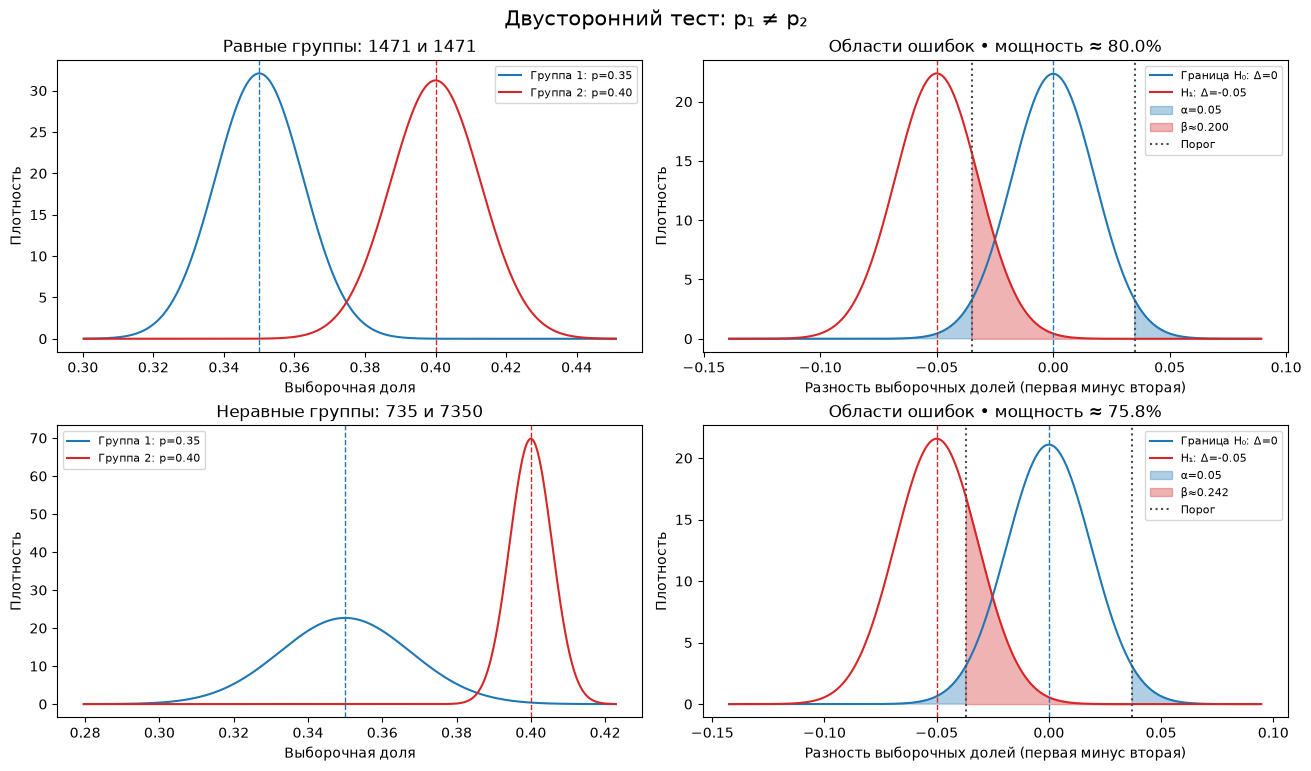

In [4]:
plot_test()

**Односторонний тест.** При $H_1:p_1>p_2$ критическая область находится только справа. Исходные $0,35<0,40$ относятся к $H_0:p_1\le p_2$, поэтому вероятность неотклонения при них нельзя называть ошибкой II рода. Чтобы показать β, **только для правых панелей второго рисунка** рассматриваем альтернативу $p_1=0,40$, $p_2=0,35$: эффект той же величины, но требуемого знака. Размеры групп остаются на своих местах.

Равные: пороги 0.0294; β ≈ 0.1235; мощность ≈ 0.8765
Неравные: пороги 0.0304; β ≈ 0.1504; мощность ≈ 0.8496


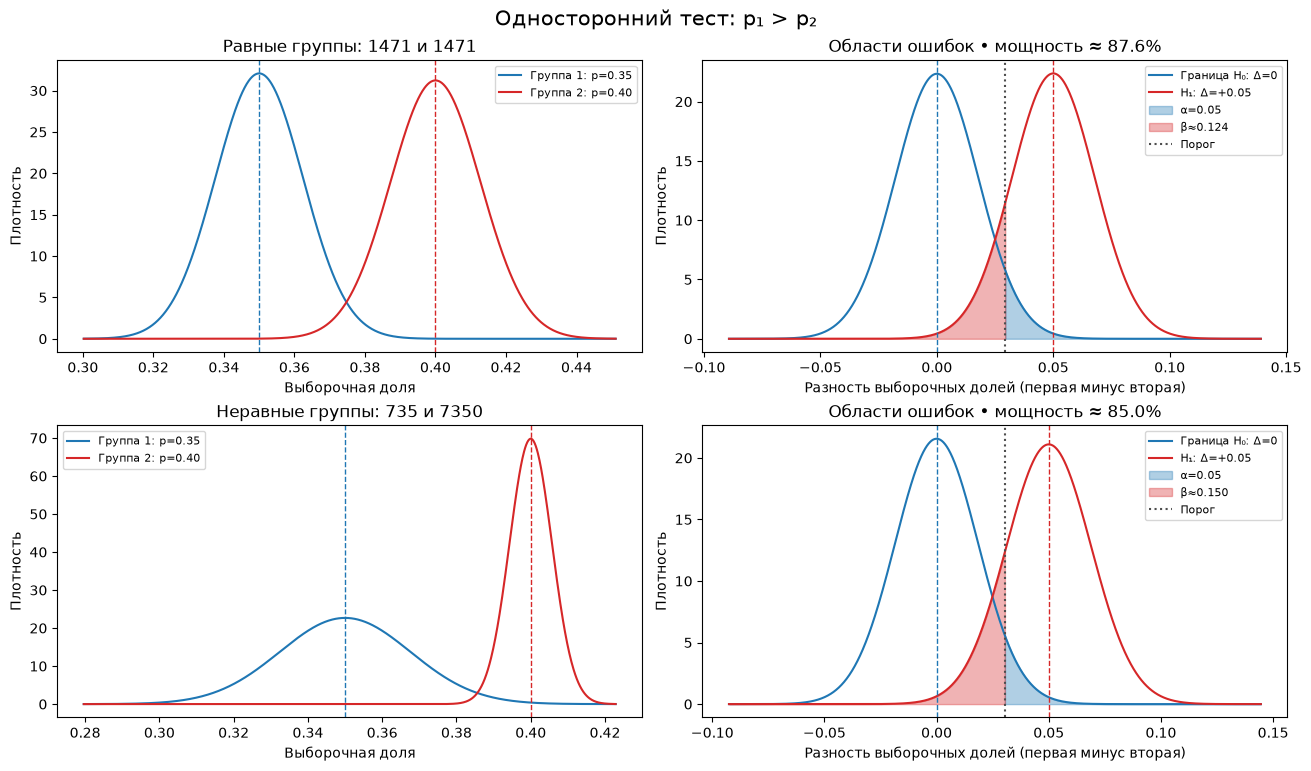

In [5]:
plot_test(one_sided=True)

**Вывод:** в двустороннем тесте мощность составляет около 80,0% для равных групп и 75,8% для групп 1:10. Даже при большем общем числе наблюдений малая первая группа ограничивает точность разности. Для отдельно заданной правосторонней альтернативы с эффектом +5 п. п. мощность составляет около 87,6% и 85,0% соответственно.

### 4. Доверительные интервалы
Используем формулу Вальда: оценка доли ± квантиль × стандартная ошибка. Число фактических успехов не дано, поэтому подставляем заданные вероятности вместо наблюдаемых долей. Получаем расчётные 95%-е интервалы по условию, а не интервалы, полученные из проведённого эксперимента.

In [6]:
# Задание 4. Границы и полная ширина интервалов
for label, (n1, n2) in designs.items():
    print(f'{label} группы:')
    for j, (p, size) in enumerate([(p1, n1), (p2, n2)], start=1):
        margin = z_two * se(p, size)
        lower, upper = p - margin, p + margin
        print(f'  Группа {j}: [{lower:.4f}, {upper:.4f}], ширина: {upper-lower:.4f}')

Равные группы:
  Группа 1: [0.3256, 0.3744], ширина: 0.0487
  Группа 2: [0.3750, 0.4250], ширина: 0.0501
Неравные группы:
  Группа 1: [0.3155, 0.3845], ширина: 0.0690
  Группа 2: [0.3888, 0.4112], ширина: 0.0224


**Вывод:** при равных размерах ширины интервалов близки: 0,0487 и 0,0501. При соотношении 1:10 интервал первой группы расширяется до 0,0690, второй — сужается до 0,0224. Для проверки различия долей используется распределение их разности из задания 3.